# Who Makes Money While Wall Street Sleeps?

*ADA 2026 — Milestone P2: initial analyses.* The full project proposal is in the [README](README.md).

## Introduction

Over the last decades, almost all of the gains of the US stock market seem to have been made **overnight**, between the close and the next open, while the **trading day** itself, when almost all trading, news reaction and price discovery happen, earned close to nothing. If returns reward risk or new information, both halves of the day should earn something. So who makes money while Wall Street sleeps?

We treat this anomaly as an investigation. We first establish the facts in our data (**the crime**), then interrogate three suspects: **risk** (do longer nights pay more?), **news** (do announcements land after the close?) and **the crowd** (does a burst of attention produce an overnight gain followed by an intraday "hangover"?). Tickers that look almost identical to famous ones provide a natural experiment (**the proof**), and the verdict comes in P3.

**Research questions**
1. Do overnight returns exceed intraday returns across US stocks and ETFs, and does the gap survive data cleaning and statistical testing?
2. Risk: do longer market closures (weekends, holidays) earn higher overnight returns?
3. News: are corporate announcements (SEC 8-K filings) concentrated after the close, and do nights without announcements still earn more?
4. Crowd: after an attention spike (abnormal volume, Google Trends), do we observe an overnight gain followed by an intraday loss?
5. Proof: do tickers that are easily mistaken for famous ones show the same pattern, compared with random placebo pairs?

**Roadmap.** Part I - The data · Part II - The crime · Part III - Risk · Part IV - News · Part V - The crowd · Part VI - The proof.

# Part I — The Data

Part I shows that we can handle a dataset of this size, that we understand what is in it, and that every transformation is justified. Every later chapter uses the table produced here.

## I.1 Reproducing the data

- `download_data()`: downloads the raw CSVs from Kaggle into `data/`.
- `build_prices()`: cleans them and writes `data/prices.parquet`.
- `load_prices()`: loads the table used by every chapter.

`data/` is not versioned. First run: ~520 MB download, 1–2 min build.

In [55]:
%load_ext autoreload
%autoreload 2

from src.data.load import download_data, build_prices, load_prices
from src.data.metadata import (
    load_metadata, exchange_breakdown, tag_special_etfs, etf_exclusion_counts, exclude_special_etfs,
)
from src.analysis.overview import (
    tickers_per_year, first_dates, size_report, removed_rows_summary, adjustment_example,
    missing_values, return_stats, night_day_correlation, volume_summary, stale_among_zero_volume,
)
from src.visualization.plots import (
    set_style, plot_tickers_per_year, plot_suspicious_share, plot_return_distributions, plot_volume_distribution,
    plot_wealth, plot_wealth_grid, plot_gap_histogram, plot_gap_heatmap, plot_filter_comparison,
)
from src.features.returns import add_returns, add_dollar_volume, portfolio_returns
from src.analysis.crime import (
    ticker_wealth, crime_headline, study_portfolios, portfolio_paths, portfolio_headlines,
    night_day_gap_by_ticker, gap_share_above_zero, gap_heatmap_table, filter_comparison,
    night_indicator_regression, block_bootstrap_ci, gap_tests_by_period,
)
from src.data.quality import (
    flag_suspicious, suspicious_share_by_year, apply_quality_filter, FILTERS,
    stale_share_by_liquidity, splice_examples, filter_summary, flag_count_by_year,
)

set_style()


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [56]:
download_data()
build_prices()
prices = load_prices()

## I.2 Source and format

*Stock Market Dataset* (Oleh Onyshchak, Kaggle): daily prices of all Nasdaq-traded stocks and ETFs, from 1962 to 1 April 2020. One CSV per ticker with `Date, Open, High, Low, Close, Adj Close, Volume`; `Adj Close` is adjusted for splits and dividends. Tickers per listing exchange:

In [57]:
meta = load_metadata()
exchange_breakdown(meta)

,stock,etf,total
exchange,,,
Nasdaq,2988,395,3383
NYSE,2520,0,2520
NYSE Arca,107,1435,1542
Cboe BZX,17,334,351
NYSE American,252,1,253
total,5884,2165,8049


Processed format: one row per (ticker, date). Raw `open` and `close` are kept to detect stale opens (I.6).

In [58]:
display(prices.head())
prices.dtypes

,ticker,date,open,close,open_adj,high_adj,low_adj,close_adj,volume,asset_type
0,A,1999-11-18,32.546494,31.473534,27.991459,30.759848,24.607878,27.068665,62546300,stock
1,A,1999-11-19,30.713520,28.880543,26.415020,26.453470,24.492531,24.838577,15234100,stock
2,A,1999-11-22,29.551144,31.473534,25.415323,27.068665,24.646326,27.068665,6577800,stock
3,A,1999-11-23,30.400572,28.612303,26.145872,26.837971,24.607880,24.607880,5975600,stock
4,A,1999-11-24,28.701717,29.372318,24.684778,25.799820,24.607878,25.261524,4843200,stock


ticker              category
date          datetime64[ns]
open                 float32
close                float32
open_adj             float32
high_adj             float32
low_adj              float32
close_adj            float32
volume                 Int64
asset_type          category
dtype: object

## I.3 Coverage over time

We count, for each year, the number of tickers with at least one trading day, for stocks and ETFs. This shows from which year the cross-section is large enough to support conclusions.

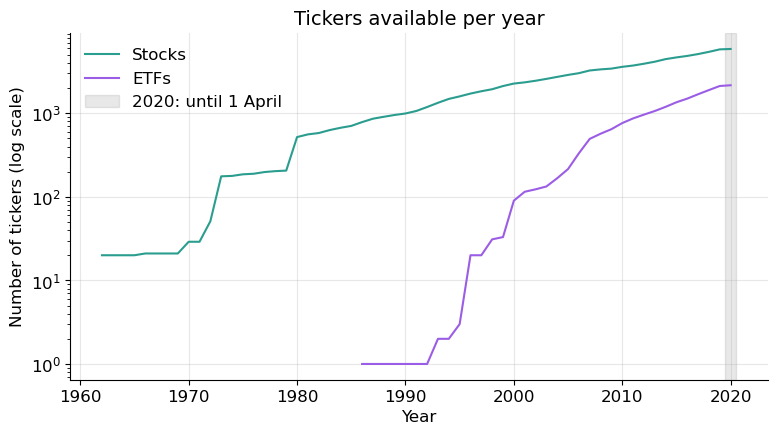

In [59]:
counts = tickers_per_year(prices)
fig = plot_tickers_per_year(counts)

In [60]:
counts.loc[[1962, 1970, 1980, 1990, 2000, 2010, 2019]]

,stock,etf
year,,
1962,20,0
1970,29,0
1980,519,0
1990,994,1
2000,2267,90
2010,3596,763
2019,5818,2121


Dates on which the most tickers have their first observation (many tickers starting on the same day reveal a change in data coverage):

In [61]:
first_dates(prices)

,n_tickers
first_date,
1980-03-17,257
1973-02-21,87
2017-10-26,39
1973-05-03,26
2000-01-03,25


**Takeaway:** Coverage grows from 20 stocks in 1962 to 5,818 in 2019, and ETFs only become numerous after 2000. The jumps in 1973 and 1980 come from the data provider, not from real listings: 87 tickers start on 21 February 1973 and 257 on 17 March 1980. Before the 1980s, cross-sectional results would rely on a few long-surviving firms. The study period is set in I.6 from the quality of opening prices.

**Survivorship bias:** The dataset only contains securities still listed in 2020: firms that went bankrupt, were delisted or were acquired are missing. Long-run average returns are therefore likely biased upwards. This affects both overnight and intraday returns, but we cannot assume it affects them equally.

## I.4 Handling the size

We compare three ways of holding the data: the raw CSVs read with pandas default dtypes, the same CSVs read with optimised dtypes, and the processed Parquet file. CSV memory and loading time are measured on a random sample of 500 files and scaled to all files; the other figures are exact.

In [62]:
size_report()

,rows,memory (GB),loading time (s),disk size (GB)
"CSV, default dtypes",28151758,6.03,25.57,2.75
"CSV, optimised dtypes",28151758,1.13,64.09,2.75
Parquet,28132072,1.24,0.48,0.71


**Choices:** `ticker` and `asset_type` are stored as `category` (a few thousand distinct values repeated millions of times), prices as `float32` (about 7 significant digits, enough for prices) and volume as nullable `Int64`. Parquet is a compressed, column-oriented format that keeps these dtypes and can read only selected columns or tickers. 

**Takeaway:** Optimised dtypes divide memory by about 5 (6.03 GB → 1.13 GB). Parsing dates makes the optimised CSV read slower (about a minute), but it is paid once in `build_prices()`: loading the Parquet file then takes about a second and uses 0.71 GB on disk instead of 2.75 GB. The Parquet table is slightly larger in memory than the optimised CSVs because it also holds the adjusted prices. The difference in row counts (28,151,758 − 28,132,072 = 19,686) is exactly the total of the rows removed in I.6.a.

## I.5 Transformations

Two transformations turn raw prices into the quantities we study: prices are first adjusted for dividends, then split into an overnight and an intraday return.

**Adjusted prices.** In this dataset `Open`, `High`, `Low` and `Close` already account for splits, but not for dividends: on an ex-dividend day the price drops by the dividend, which is not a loss for shareholders. `Adj Close` accounts for both, so we apply its daily factor to the other prices:

$$f_t = \frac{\text{Adj Close}_t}{\text{Close}_t}, \qquad \text{open\_adj}_t = \text{Open}_t \times f_t$$

(same for `high_adj` and `low_adj`; `close_adj` is `Adj Close`). All prices of a day are rescaled by the same factor, so returns within a day are unchanged and returns across an ex-dividend date include the dividend.

Example: Apple went ex-dividend on 7 February 2020. Its overnight return from raw and from adjusted prices:

In [63]:
adjustment_example(prices, ticker="AAPL", date="2020-02-07")

,previous close,open,overnight return (%)
raw,325.21,322.37,-0.87
adjusted,324.44,322.37,-0.64


**Takeaway:** The raw previous close (325.21) exceeds the adjusted one (324.44) by \$0.77, the dividend paid. Without adjustment, the night would show −0.87 % instead of −0.64 %: the dividend would be counted as an overnight loss.

**Overnight and intraday returns**, computed within each ticker:

$$r^{\text{night}}_t = \frac{\text{open\_adj}_t}{\text{close\_adj}_{t-1}} - 1, \qquad r^{\text{day}}_t = \frac{\text{close\_adj}_t}{\text{open\_adj}_t} - 1$$

The night runs from the previous close to the open, the day from the open to the close. $t-1$ is the previous **trading day of the market**, defined as the previous date in the union of all dates present in the table (every day on which at least one ticker traded). If the ticker has no row on that day (first observation, gap, removed row), $r^{\text{night}}_t$ is missing, so a night never hides several days. Weekends and holidays are kept: they are one (long) night.

## I.6 Cleaning and data quality

### I.6.a Rows removed by the pipeline

Rows that cannot be used at all are removed by `build_prices()` and stored in `data/dropped_rows.parquet` with their reason:

In [64]:
removed_rows_summary()

,rows,share (%),tickers
reason,,,
negative_adj,18967,0.067,16
missing,683,0.002,267
close_zero,36,0.0,18
total,19686,0.07,291


`negative_adj` comes from an erroneous dividend adjustment in the source data on 16 tickers (early adjusted prices become negative); only the affected rows are removed, not the tickers. Raw `Open` values equal to 0 are not removed but set to missing, and flagged below.

### I.6.b Suspicious observations

Other observations are **flagged, not removed**, by `flag_suspicious()`, after computing the returns of I.5. The three *open* flags indicate an opening price that was probably not recorded:

- `open_missing`: raw `Open` was 0;
- `open_equals_prev_close`: `Open(t) = Close(t−1)`, so the overnight return is exactly 0;
- `open_equals_close`: `Open(t) = Close(t)`, so the intraday return is exactly 0;
- `flat_day`: open = high = low = close;
- `zero_volume`: no share traded;
- `extreme_return`: overnight or intraday return above 50 % in absolute value;
- `spliced_history`: the row comes before the ticker's last jump of the raw close by a factor of 10 or more from one day to the next. Raw prices already include splits, so such a jump often means that the history of another security was attached to the ticker. A true crash of that size would also be flagged, and the history before it dropped: the examples below show both cases.

`stale_open` is the union of the three open flags. The next cell applies the formulas of I.5 and the flags:

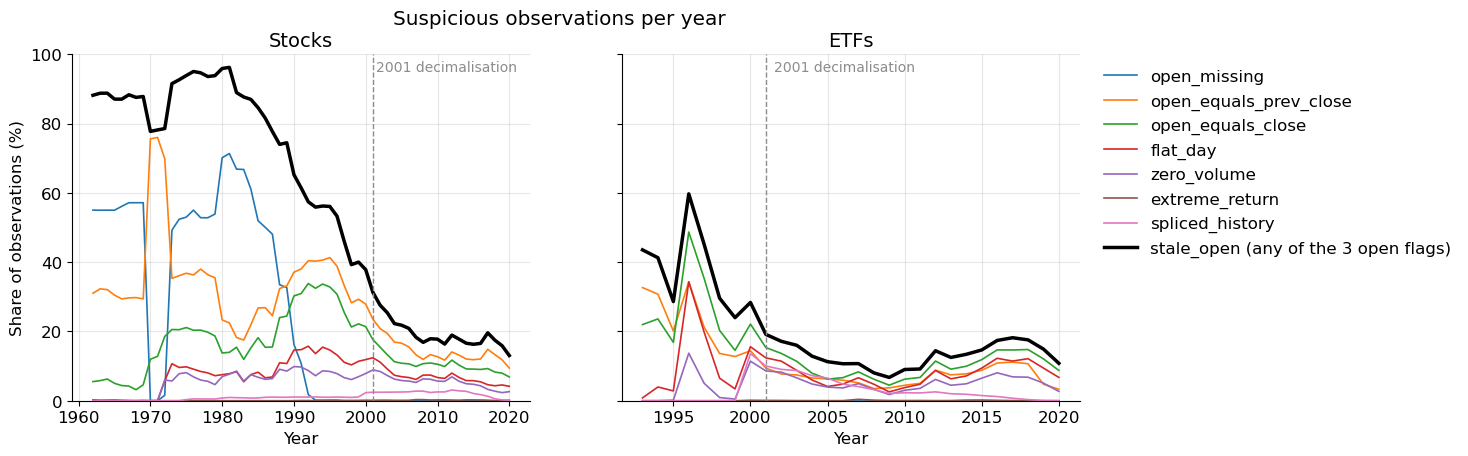

In [65]:
prices = flag_suspicious(add_dollar_volume(add_returns(prices)))
share = suspicious_share_by_year(prices)
fig = plot_suspicious_share(share)

Share of flagged stock observations in selected years (the `spliced_history` column is the one cited below):

In [66]:
(100 * share.loc["stock"].loc[[1980, 1990, 1997, 2000, 2001, 2005, 2019]]).round(1)

,open_missing,open_equals_prev_close,open_equals_close,flat_day,zero_volume,extreme_return,spliced_history,stale_open
year,,,,,,,,
1980,70.1,23.3,13.8,7.5,7.0,0.0,0.8,95.9
1990,16.2,37.1,30.2,14.6,9.9,0.0,1.1,65.2
1997,0.0,33.3,25.5,11.1,6.7,0.0,1.0,46.0
2000,0.0,27.9,21.4,11.9,7.9,0.1,2.3,37.8
2001,0.0,23.5,17.6,12.4,8.9,0.1,2.4,31.3
2005,0.0,16.6,10.8,6.9,5.8,0.1,2.5,21.8
2019,0.0,11.8,8.0,4.5,2.3,0.0,0.2,15.9


Missing opens around the start of the study period (counts, not shares: 88 rows in 1997 round to 0.0 %):

In [67]:
flag_count_by_year(prices, "open_missing").loc[1995:1999]

year
1995    647
1996    709
1997     88
1998      0
1999      0
Name: open_missing, dtype: int64

Tickers whose history is cut by `spliced_history`, with three hand-checked examples:

In [68]:
print(f"{prices.loc[prices.spliced_history, 'ticker'].nunique()} tickers, {prices.spliced_history.sum():,} rows")
splice_examples(prices, ["FTAI", "BILL", "NVR"])

323 tickers, 503,604 rows


,first date,jump date,close before,close after,flagged rows
FTAI,1996-01-03,2015-05-14,759.90,17.00,4845
BILL,2014-07-21,2019-12-12,2.88,35.50,146
NVR,1985-07-22,1993-10-01,0.38,10.25,2073


**Takeaway:** Before 1997, open prices are largely unusable: in 1980, 70.1 % of stock opens are missing and 95.9 % are stale. Missing opens fall to 88 rows in 1997 and to 0 from 1998. Stale opens remain frequent: they fall from 37.8 % of stock observations in 2000 to 21.8 % in 2005, a decline that is consistent with the 2001 decimalisation of US prices, and still reach 15.9 % in 2019. ETFs show the same pattern at a lower level (28.4 % stale in 2000, 11.3 % in 2005, 14.9 % in 2019). Extreme returns are rare (at most 0.2 % per year). `spliced_history` flags 323 tickers (up to 2.5 % of stock observations per year; 13.6 % of ETF observations in 2000). FTAI and BILL are splices (another series glued before the listing); NVR in 1993 may be a real recapitalisation: the rule can drop a true history.

Stale opens are not all recording errors. Share of stale opens (%) by quintile of the previous day's dollar volume (Q1 = least traded) and by previous close, from 1998:

In [69]:
stale_share_by_liquidity(prices, start_year=1998)

,Q1,Q2,Q3,Q4,Q5,price < $5,price >= $5
asset_type,,,,,,,
etf,40.8,8.7,6.7,6.3,5.0,68.1,13.5
stock,49.4,21.1,15.3,10.4,7.2,38.6,17.5


**Takeaway:** Stale opens are concentrated among illiquid names: 49.4 % of stock days in Q1, against 7.2 % in Q5; 38.6 % when the previous close is below \$5, against 17.5 % above. Even the most traded quintile still has 7.2 % stale opens, so some equalities are genuine prices. Removing them selects observations by their return. Whether that choice changes the night–day gap is tested in II.3.

> **Decision.** The study period starts in **1998**, the first year with 0 missing opens (88 remain in 1997). The main analysis uses a **liquidity filter**: it drops a row when the previous close is below \$5 or the previous day's dollar volume is in the bottom 20 % of its year, and also drops missing opens, extreme returns and spliced histories. Previous-day values are known before the night starts. This is the usual finance screen; it does not select on the return of the day itself. Section II.3 compares three versions: this liquidity filter, a stale-open filter, and a light filter (missing opens, extreme returns and spliced histories only). Whether the choice affects the gap is tested there.

In [70]:
filter_summary(prices, start_year=1998)

,rows kept,% of all rows,% of study period
liquidity,17268524,61.4,74.1
stale,18639588,66.3,80.0
light,22826437,81.1,98.0


In [71]:
filtered = apply_quality_filter(prices, start_year=1998, drop_flags=FILTERS["liquidity"])
print(f"Main (liquidity) filter: kept {len(filtered) / len(prices):.1%} of all observations")

Main (liquidity) filter: kept 61.4% of all observations


## I.7 Descriptive statistics

Missing values per column in the cleaned table (`prices`, all years):

In [72]:
missing_values(prices, ["open", "close", "open_adj", "high_adj", "low_adj", "close_adj", "volume", "r_night", "r_day"])

,missing,share (%)
open,1176088,4.18
close,0,0.00
open_adj,1176088,4.18
high_adj,153,0.00
low_adj,153,0.00
close_adj,0,0.00
volume,0,0.00
r_night,1210137,4.30
r_day,1176088,4.18


`open` is missing where the raw open was 0 (I.6), and returns are missing when the open is missing or the previous trading day is absent. `high_adj` and `low_adj` are missing where `High < Low`.

The return statistics below use the main analysis sample (`filtered`: 1998 onwards, liquidity filter). Distribution of overnight and intraday returns:

In [73]:
return_stats(filtered)

n  mean (%)  median (%)  std (%)  p1 (%)  p99 (%)  \
asset_type return                                                             
stock      night   14182322     0.039       0.000    1.515  -4.078    4.286   
           day     14186620    -0.003       0.000    2.562  -7.317    7.568   
etf        night    3079774     0.039       0.039    1.205  -3.475    3.384   
           day      3081904    -0.027       0.000    1.373  -4.153    3.921   

                   skewness  excess kurtosis  
asset_type return                             
stock      night      0.008           95.514  
           day        0.452           21.269  
etf        night     -0.156           70.693  
           day       -0.258           39.686

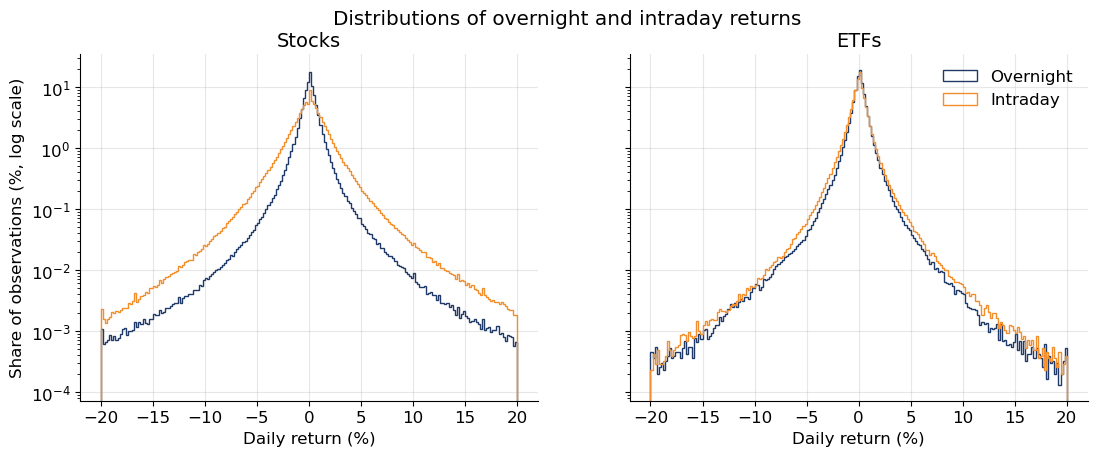

In [74]:
fig = plot_return_distributions(filtered)

**Takeaway:** Returns are strongly heavy-tailed: excess kurtosis ranges from 21 to 96 (0 for a normal distribution). The **mean** overnight return of stocks is 0.039 % **per day**, against −0.003 % intraday; for ETFs the means are 0.039 % overnight and −0.027 % intraday. Medians sit at 0. The trading session is more volatile than the night (stock standard deviation 2.56 % vs 1.52 %) even though it lasts about 6 h 30 against 17 h 30, so per hour the gap is larger still. These pooled figures give more weight to tickers with long histories; Part II tests the gap properly, with medians and robust tests alongside means because of the heavy tails.

Correlation between the overnight and the intraday return of the same day, on `filtered`. Pearson measures a linear relation and is sensitive to extreme values; Spearman uses ranks, so it is robust to heavy tails:

In [75]:
night_day_correlation(filtered)

,pearson,spearman
asset_type,,
stock,-0.080,-0.071
etf,-0.023,-0.014


**Takeaway:** Overnight and intraday returns are negatively correlated, more for stocks (Pearson −0.08, Spearman −0.07) than for ETFs (−0.02, −0.01): part of the overnight move tends to be reversed during the day. A noisy opening price also creates this mechanically (an open that is too high makes the night look better and the day worse). The correlation is weaker here than on unfiltered data, which is consistent with that mechanical channel.

Distribution of daily **dollar** volume (`prices`, all years: this describes the raw cleaned table, not `filtered`):

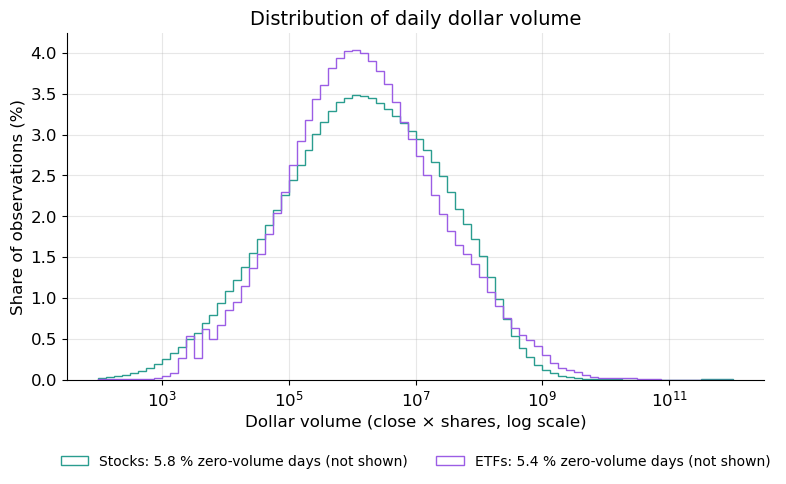

In [76]:
fig = plot_volume_distribution(prices)

In [77]:
volume_summary(prices)

,zero-volume days (%),p1 ($),median ($),p99 ($)
asset_type,,,,
stock,5.8,1250,1453500,497385426
etf,5.4,2852,1392248,1108722747


In [78]:
stale_among_zero_volume(prices)

zero-volume days           1610344.0
of which stale open (%)         92.7
dtype: float64

**Takeaway:** On traded days, stock dollar volume ranges from \$1,250 (1st percentile) to \$497 million (99th), about five orders of magnitude, hence the log scale. In dollars, the median ETF (\$1.39 million) is close to the median stock (\$1.45 million): the gap seen in share counts is mostly a difference of price per share. 5.8 % of stock days and 5.4 % of ETF days have zero volume; 92.7 % of those zero-volume days also have a stale open.

# Part II — The Crime (preliminary results)

These results establish that the anomaly is present in our data, which makes the project feasible. They will be extended and tested further in P3.

Invested only overnight, \$1 in SPY grows several-fold over 1998–2020; invested only during the trading day, it loses money (II.1). That is strange: the session is when almost all trading, price discovery and news reaction happen, so both halves should earn something if returns reward risk or information.

This chapter is **descriptive** (lecture 06): it establishes the fact before asking why. Four questions: Does the crime exist (SPY)? Is it universal? Does it survive the quality filters of Part I? Is the gap distinguishable from zero?

## II.1 Does the crime exist? (SPY)

The value of \$1 invested only in one half of the day, and the convention used to annualise:

$$V_T = \prod_{t \le T} (1 + r_t), \qquad \text{annualised mean} = 252 \times \text{mean daily return}$$

252 is the usual number of US trading days in a year. Buy-and-hold compounds both halves each day: $(1+r^{\text{night}}_t)(1+r^{\text{day}}_t)$.

Log returns split the close-to-close return exactly (lecture 05, log outcomes for heavy tails):

$$\underbrace{\log\frac{\text{close\_adj}_t}{\text{close\_adj}_{t-1}}}_{\text{total}} = \underbrace{\log(1+r^{\text{night}}_t)}_{\text{night}} + \underbrace{\log(1+r^{\text{day}}_t)}_{\text{day}}$$

Their sums tell us what share of the total return comes from the night. SPY, the largest US equity ETF, from the start of the study period:

,first date,last date,days,value of $1,annualised mean (%),share of log return (%)
overnight,1998-01-02,2020-04-01,5598,4.74,7.64,116.61
intraday,1998-01-02,2020-04-01,5598,0.80,0.29,-16.61
buy-and-hold,1998-01-02,2020-04-01,5598,3.80,7.98,100.00


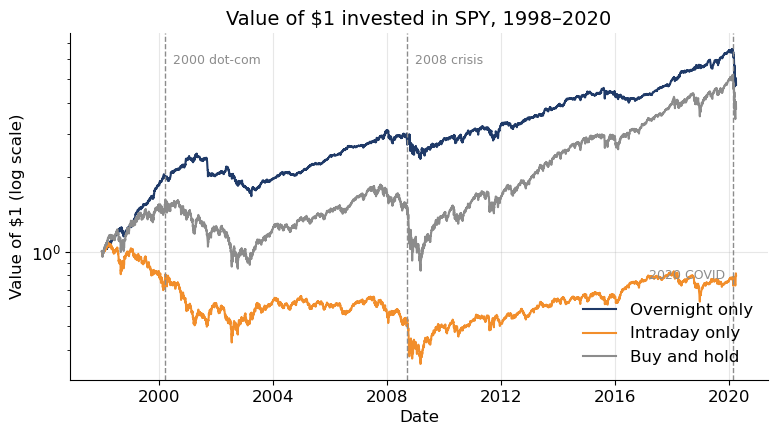

In [79]:
wealth = ticker_wealth(filtered, "SPY")
fig = plot_wealth(wealth, "Value of $1 invested in SPY, 1998–2020")
crime_headline(filtered, "SPY")

**Takeaway:** \$1 invested in SPY from 2 January 1998 to 1 April 2020 became \$4.74 overnight only, \$0.80 during the trading day only, and \$3.80 buy-and-hold. The night's annualised mean return is 7.64 %, the day's 0.29 %. Because the day lost money, the night accounts for 116.6 % of the total log return. The trading session, where almost everything happens, earned close to nothing; the closed market earned the gain. II.2 asks whether this is only SPY.

## II.2 Is it universal?

A portfolio return on day $t$ is the cross-section of the tickers available that day:

- equal-weighted: $r^{\text{EW}}_t = \frac{1}{N_t}\sum_i r_{i,t}$;
- dollar-volume-weighted: $r^{\text{DV}}_t = \sum_i w_{i,t}\, r_{i,t}$, with $w_{i,t}$ proportional to the **mean** of `close × volume` over the previous **20** trading days.

The 20-day window is known before the night starts. A one-day volume spike would overweight names that just attracted attention — the crowd hypothesis of Part V — so a month of volume is a more stable liquidity weight. This is still not a market-cap weighting: market capitalisation is not in the dataset.

Before aggregating, we drop ETFs whose US "night" is not mysterious, or whose returns are mechanical. A name is flagged if `security_name` contains one of these keywords (case-insensitive):

- foreign markets: `japan`, `europe`, `eurozone`, `emerging`, `china`, `chinese`, `india`, `brazil`, `korea`, `mexico`, `australia`, `hong kong`, `taiwan`, `russia`, `latin`, `eafe`, `frontier`, `international`, `germany`, `united kingdom`, `britain`, `asia`, `pacific`, `africa`;
- leveraged / inverse: `ultrashort`, `ultrapro`, `ultra `, `inverse`, `2x`, `3x`, `bear 1x`/`2x`/`3x`, `bull 2x`/`3x`, `leveraged`, `proshares short`.

These ETFs can be put back as a sanity check; they are not in the main figures.

In [80]:
meta = tag_special_etfs(meta)
etf_exclusion_counts(meta)

,ETFs
all ETFs,2165
foreign,418
leveraged / inverse,191
both,31
kept in the main analysis,1587


In [81]:
study = exclude_special_etfs(filtered, meta)
print(f"Study sample: {len(study):,} rows after ETF exclusions")
ports = study_portfolios(study)
portfolio_headlines(ports)

Study sample: 16,456,113 rows after ETF exclusions


first date   last date  days  \
portfolio              strategy                                     
Stocks, equal-weighted overnight     1998-01-02  2020-04-01  5598   
                       intraday      1998-01-02  2020-04-01  5598   
                       buy-and-hold  1998-01-02  2020-04-01  5598   
Stocks, dollar-volume  overnight     1998-02-02  2020-04-01  5578   
                       intraday      1998-02-02  2020-04-01  5578   
                       buy-and-hold  1998-02-02  2020-04-01  5578   
ETFs, equal-weighted   overnight     1998-01-02  2020-04-01  5598   
                       intraday      1998-01-02  2020-04-01  5598   
                       buy-and-hold  1998-01-02  2020-04-01  5598   
ETFs, dollar-volume    overnight     1998-02-02  2020-04-01  5578   
                       intraday      1998-02-02  2020-04-01  5578   
                       buy-and-hold  1998-02-02  2020-04-01  5578   

                                     value of $1  annualised mean (%)  \
portfolio              strategy                                         
Stocks, equal-weighted overnight            9.10                10.39   
                       intraday             1.04                 1.38   
                       buy-and-hold         9.47                11.99   
Stocks, dollar-volume  overnight           23.65                15.21   
                       intraday             0.24                -4.43   
                       buy-and-hold         5.70                10.82   
ETFs, equal-weighted   overnight           21.63                14.40   
                       intraday             0.16                -7.41   
                       buy-and-hold         3.49                 7.09   
ETFs, dollar-volume    overnight            8.90                10.61   
                       intraday             0.29                -3.79   
                       buy-and-hold         2.57                 6.83   

                                     share of log return (%)  
portfolio              strategy                               
Stocks, equal-weighted overnight                       98.23  
                       intraday                         1.77  
                       buy-and-hold                   100.00  
Stocks, dollar-volume  overnight                      181.70  
                       intraday                       -81.70  
                       buy-and-hold                   100.00  
ETFs, equal-weighted   overnight                      246.16  
                       intraday                      -146.16  
                       buy-and-hold                   100.00  
ETFs, dollar-volume    overnight                      231.25  
                       intraday                      -131.25  
                       buy-and-hold                   100.00

Equal-weighted and dollar-volume-weighted paths for stocks, then for the remaining ETFs:

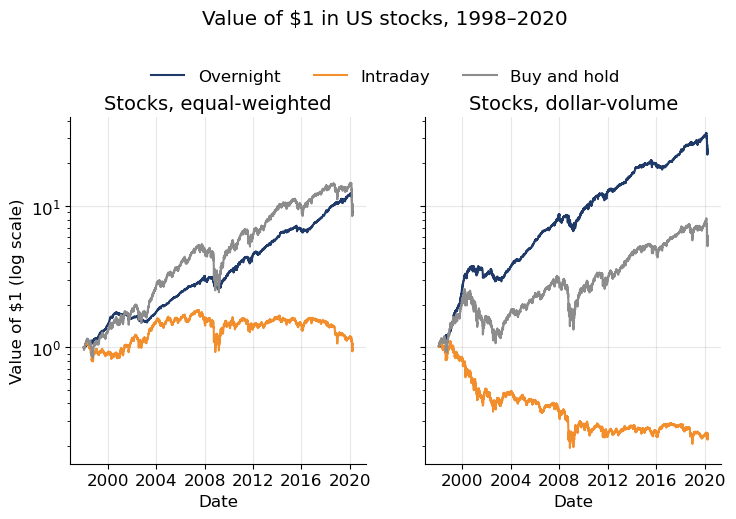

In [82]:
fig = plot_wealth_grid(
    portfolio_paths(ports, ["Stocks, equal-weighted", "Stocks, dollar-volume"]),
    "Value of $1 in US stocks, 1998–2020",
)

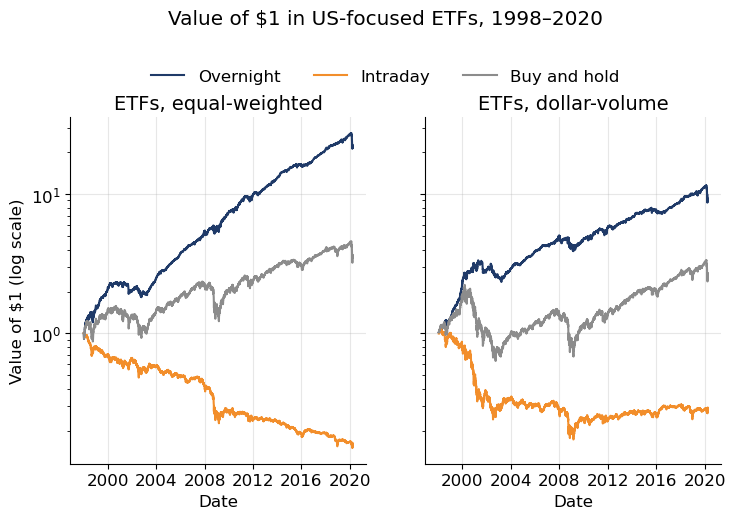

In [83]:
fig = plot_wealth_grid(
    portfolio_paths(ports, ["ETFs, equal-weighted", "ETFs, dollar-volume"]),
    "Value of $1 in US-focused ETFs, 1998–2020",
)

**Takeaway:** The crime is not only SPY. \$1 in an equal-weighted stock portfolio became \$9.10 overnight and \$1.04 during the day; dollar-volume-weighted stocks became \$23.65 overnight and \$0.24 during the day. US-focused ETFs show the same split (equal-weighted: \$21.63 vs \$0.16). The trading day earns little or loses money; the night earns the gain. Dollar-volume weights, which load on liquid names, make the split larger, not smaller.

For each ticker with at least 252 paired returns, the annualised gap `mean(r_night) − mean(r_day)`:

,tickers,night > day (%),median gap (%)
asset_type,,,
stock,4885,58.6,6.2
etf,1112,84.8,15.4


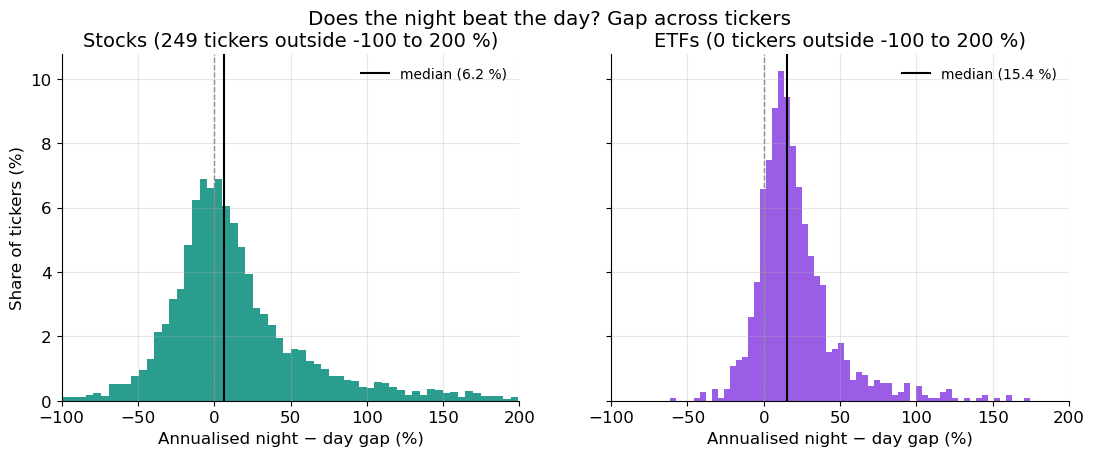

In [84]:
gaps = night_day_gap_by_ticker(study)
fig = plot_gap_histogram(gaps)
gap_share_above_zero(gaps)

**Takeaway:** The night earns more than the day for 58.6 % of stocks and 84.8 % of the remaining ETFs. The median annualised gap is 6.2 % for stocks and 15.4 % for ETFs. The pattern is common, not a handful of famous tickers. It is not universal among stocks: about two in five have the opposite sign.

Where and when: annualised gap by year, for stocks, ETFs, and quintiles of the 20-day lagged dollar volume (Q1 = least traded). 2020 is omitted (data end on 1 April):

,Stocks,ETFs,Q1,Q2,Q3,Q4,Q5
year,,,,,,,
2000,17.2,20.4,-14.2,-6.5,13.7,37.1,50.3
2008,11.4,49.7,40.6,23.0,4.7,-0.7,11.2
2009,-0.5,21.7,29.4,7.0,-0.6,-14.0,-10.2
2019,9.6,11.0,21.1,11.7,6.1,4.3,3.6


,Stocks,ETFs,Q1,Q2,Q3,Q4,Q5
mean,10.2,22.7,10.0,11.1,8.9,9.9,13.6


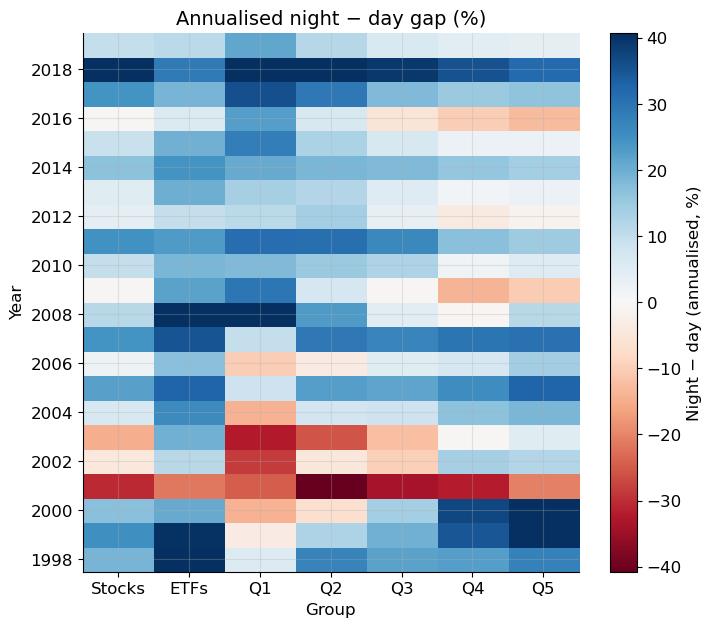

In [85]:
heat = gap_heatmap_table(study)
fig = plot_gap_heatmap(heat)
display(heat.loc[[2000, 2008, 2009, 2019]])
heat.mean().to_frame("mean").T.round(1)

**Takeaway:** The gap is positive in most years and groups (column means shown under the figure: 10.2 % for stocks, 22.7 % for ETFs). It is not confined to illiquid names: in 2019 it is 3.6 % even in Q5. Exceptions exist: stocks in 2009 (−0.5 %), and some quintiles in 2000 and 2008 change sign. The 2008 crisis is a large *positive* gap for ETFs (49.7 %): the night earned while the session sold off.

## II.3 Does it survive data cleaning?

Section I.6 announced three filters. The next table and figure apply each of them to SPY and to equal-weighted stocks (no ETF exclusion here, so the comparison isolates the filter):

,SPY night,SPY day,SPY gap,EW stocks night,EW stocks day,EW stocks gap
liquidity,7.64,0.29,7.35,10.39,1.38,9.01
stale,7.48,-0.27,7.75,13.48,9.49,4.00
light,7.64,0.29,7.35,9.05,7.78,1.27


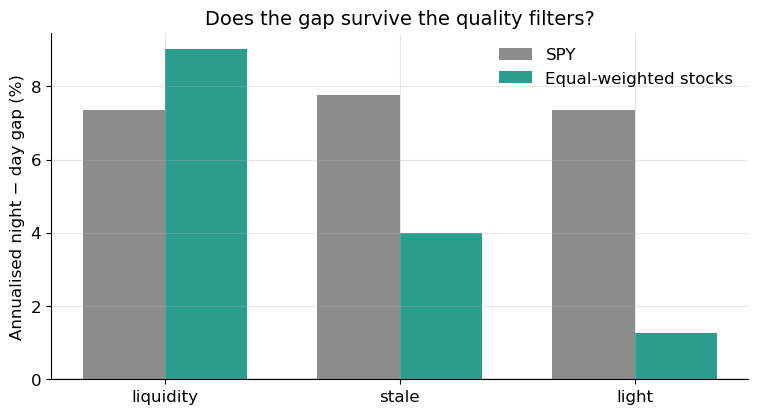

In [86]:
cmp = filter_comparison(prices, start_year=1998, filters=FILTERS)
fig = plot_filter_comparison(cmp)
cmp

**Takeaway:** On SPY the gap is almost the same under every filter (7.35 % liquidity and light, 7.75 % stale). On equal-weighted stocks it shrinks when we keep illiquid names: 9.01 % with the liquidity filter, 4.00 % with the stale-open filter, 1.27 % with the light filter. On SPY the crime is not created by how stale opens are treated; in the cross-section it is concentrated among liquid names. With the light filter, the equal-weighted stock *day* return is 7.78 % a year, against 1.38 % under the liquidity filter: illiquid names earn a lot during the session, which is consistent with bid–ask bounce (see the limits below). Whether the liquid sample is the economically relevant one is a choice; the three numbers are the robustness check.

## II.4 Is it statistically significant?

Comparing two separately computed means ignores that night and day of the same date are paired. Lecture 05 stacks them and estimates one coefficient:

$$r_{t,s} = \alpha + \beta \cdot \mathbb{1}[s=\text{night}] + \varepsilon_{t,s}$$

$\beta$ is the mean night − day difference. Standard errors are **clustered by date**, so the two halves of the same day are not treated as independent.

Errors are also autocorrelated across days. A **block bootstrap** of $d_t = r^{\text{night}}_t - r^{\text{day}}_t$ (blocks of 21 consecutive trading days, 1,000 resamples) gives a second 95 % interval. We report simple and log returns, and the split before / after 2008.

SPY, liquidity sample:

In [87]:
spy = study[study["ticker"] == "SPY"]
night_indicator_regression(spy)

,beta daily (%),beta annualised (%),SE daily (%),CI 95% low,CI 95% high,p-value,n days
0,0.0292,7.351,0.0163,-0.6877,15.3898,0.0731,5598


In [88]:
block_bootstrap_ci(spy["r_night"] - spy["r_day"])

,block,resamples,mean daily (%),mean annualised (%),CI 95% low,CI 95% high
0,21,1000,0.03,7.35,0.3,15.69


In [89]:
gap_tests_by_period(spy)

beta daily (%)  beta annualised (%)  SE daily (%)  \
sample    return                                                      
1998–2020 simple          0.0292               7.3510        0.0163   
          log             0.0318               8.0047        0.0163   
1998–2007 simple          0.0636              16.0314        0.0241   
          log             0.0673              16.9531        0.0241   
2008–2020 simple          0.0011               0.2750        0.0220   
          log             0.0028               0.7102        0.0222   

                  CI 95% low  CI 95% high  p-value  n days  
sample    return                                            
1998–2020 simple     -0.6877      15.3898   0.0731  5598.0  
          log        -0.0605      16.0699   0.0517  5598.0  
1998–2007 simple      4.1200      27.9428   0.0083  2514.0  
          log         5.0296      28.8766   0.0053  2514.0  
2008–2020 simple    -10.6133      11.1633   0.9605  3084.0  
          log       -10.2333      11.6536   0.8988  3084.0

Equal-weighted stocks, same tests:

In [90]:
ew = ports["Stocks, equal-weighted"]
night_indicator_regression(ew)

,beta daily (%),beta annualised (%),SE daily (%),CI 95% low,CI 95% high,p-value,n days
0,0.0357,9.0053,0.0142,1.9978,16.0128,0.0118,5598


In [91]:
block_bootstrap_ci(ew["r_night"] - ew["r_day"])

,block,resamples,mean daily (%),mean annualised (%),CI 95% low,CI 95% high
0,21,1000,0.04,9.01,2.95,16.13


**Takeaway:** Over the whole period, the SPY result is **borderline and method-dependent**: clustered standard errors give 7.35 % with a 95 % CI of [−0.69, 15.39] (p = 0.073, includes 0); the block bootstrap gives [0.30, 15.69] (excludes 0). The more important pattern is the **2008 break**: 16.0 % in 1998–2007 (p = 0.008) and 0.28 % in 2008–2020 (p = 0.96). Log returns say the same. First tests on equal-weighted stocks support a gap (9.01 %, p = 0.012, bootstrap [2.95, 16.13]). These tests will be extended in P3.

## Conclusion

- **The crime appears on SPY** (1998–2020): \$1 became \$4.74 overnight and \$0.80 during the day. The night's share of the log return is 116.6 % because the day lost money.
- **It is typical, not unique.** Equal-weighted stocks, dollar-volume-weighted stocks and US-focused ETFs all earn almost everything overnight. The night beats the day for 58.6 % of stocks and 84.8 % of those ETFs.
- **On SPY it does not depend on how stale opens are treated; in the cross-section it is concentrated among liquid names.** First tests support a gap for equal-weighted stocks and for SPY before 2008. **On SPY after 2008 the gap is indistinguishable from zero** — a break that P3 should put at the centre, not treat as a footnote.

**Limits of this chapter.** Survivorship bias (I.3) still applies. Opening prices remain noisy for illiquid names; we showed three filters rather than claiming one is true. There is no market cap, only liquidity weights. Daily equal-weighted portfolios of less liquid names are inflated by bid–ask bounce; the liquidity filter reduces that bias but does not remove it. Foreign and leveraged ETFs were dropped by a keyword list that can miss or over-exclude. The post-2008 fade on SPY is a fact in these data, not an explanation.

## Next steps for P3

1. **The 2008 break.** Track the night–day gap in a rolling 3-year window, and ask whether the anomaly faded once it was known.
2. **Return and volatility per hour**, to answer the objection that the night is simply longer.
3. **COVID zoom** (February–April 2020): did the crash and the rebound happen overnight or during the day?
4. **Weighting and ETF robustness.** We already use a 20-day dollar-volume window. Still to check: volatility and commodity ETFs, which can still pull an equal-weighted ETF book.
5. **Transaction costs** of an overnight-only strategy, for the verdict.
6. **One filter for the whole team.** Every later chapter uses the same sample: the group must confirm the liquidity filter as the common default.

**Who is guilty?** Part III asks whether longer nights pay more (risk). Part IV asks whether news lands after the close. Part V asks whether a crowd of attention produces an overnight gain and an intraday hangover. Part VI uses mistaken tickers as a natural experiment. The verdict is for P3.